In [1]:
import os, gc, numpy as np, deepchem as dc
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

DATA = os.path.expanduser("~/ai-nose/data")
OUT  = os.path.expanduser("~/ai-nose/models/baseline"); os.makedirs(OUT, exist_ok=True)
train = dc.data.DiskDataset(f"{DATA}/train")
valid = dc.data.DiskDataset(f"{DATA}/valid")
test  = dc.data.DiskDataset(f"{DATA}/test")

def morgan_counts(smiles_list, radius, size=2048):
    gen = rdFingerprintGenerator.GetMorganGenerator(radius=radius, fpSize=size)
    return np.array([gen.GetCountFingerprintAsNumPy(Chem.MolFromSmiles(s)) for s in smiles_list], dtype=np.float32)

def mean_auroc(y_true, y_prob):
    scores = [roc_auc_score(y_true[:, j], y_prob[:, j])
              for j in range(y_true.shape[1]) if 0 < y_true[:, j].sum() < len(y_true)]
    return float(np.mean(scores))

def rf_probs(rf, X):
    return np.column_stack([p[:, 1] if p.shape[1] == 2 else np.zeros(len(X)) for p in rf.predict_proba(X)])

def make_rf():
    # At least 5 molecules per leaf keeps the trees, and the memory use, small
    return RandomForestClassifier(n_estimators=200, min_samples_leaf=5, max_features="sqrt",
                                  n_jobs=4, random_state=0)

# 1. Pick the fingerprint radius on validation, one forest at a time
results = {}
for radius in [2, 3]:
    rf = make_rf()
    rf.fit(morgan_counts(train.ids, radius), train.y)
    results[radius] = mean_auroc(valid.y, rf_probs(rf, morgan_counts(valid.ids, radius)))
    print(f"radius {radius}: valid AUROC {results[radius]:.3f}", flush=True)
    del rf; gc.collect()   # free the memory before training the next one

# 2. Retrain the best one and score both models on the same test set
radius = max(results, key=results.get)
rf = make_rf()
rf.fit(morgan_counts(train.ids, radius), train.y)
rf_test = rf_probs(rf, morgan_counts(test.ids, radius))
del rf; gc.collect()
np.save(f"{OUT}/test_rf_probs.npy", rf_test)

ens_test = np.load(os.path.expanduser("~/ai-nose/models/ensemble/test_ensemble_probs.npy"))
print(f"\nRandom forest (radius {radius}) test AUROC: {mean_auroc(test.y, rf_test):.3f}")
print(f"GNN ensemble test AUROC:               {mean_auroc(test.y, ens_test):.3f}")

# 3. 95% confidence intervals: resample the test set 1,000 times
rng = np.random.default_rng(0)
n = len(test.y)
g_s, r_s, d_s = [], [], []
for _ in range(1000):
    idx = rng.integers(0, n, n)
    g, r = mean_auroc(test.y[idx], ens_test[idx]), mean_auroc(test.y[idx], rf_test[idx])
    g_s.append(g); r_s.append(r); d_s.append(g - r)
ci = lambda a: f"{np.percentile(a, 2.5):.3f} to {np.percentile(a, 97.5):.3f}"
print(f"\nGNN ensemble 95% CI:  {ci(g_s)}")
print(f"Random forest 95% CI: {ci(r_s)}")
print(f"GNN minus RF 95% CI:  {ci(d_s)}")

No normalization for SPS. Feature removed!
No normalization for AvgIpc. Feature removed!
No normalization for NumAmideBonds. Feature removed!
No normalization for NumAtomStereoCenters. Feature removed!
No normalization for NumBridgeheadAtoms. Feature removed!
No normalization for NumHeterocycles. Feature removed!
No normalization for NumSpiroAtoms. Feature removed!
No normalization for NumUnspecifiedAtomStereoCenters. Feature removed!
No normalization for Phi. Feature removed!
Skipped loading material featurizer, missing a dependency. No module named 'ase'
/home/sachinkukkar/miniforge3/envs/open_pom/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Skipped loading some Tensorflow models, missing a dependency. No module named 'tensorflow'
Skipped loading some PyTorch models, missing a dependency. No module

radius 2: valid AUROC 0.854
radius 3: valid AUROC 0.853

Random forest (radius 2) test AUROC: 0.862
GNN ensemble test AUROC:               0.891

GNN ensemble 95% CI:  0.880 to 0.901
Random forest 95% CI: 0.849 to 0.874
GNN minus RF 95% CI:  0.021 to 0.036


GNN beats the random forest on 109 of 138 smell words

Biggest GNN wins:
  gassy          GNN 0.97 vs RF 0.75   (3 test molecules)
  lavender       GNN 0.97 vs RF 0.78   (5 test molecules)
  black currant  GNN 0.96 vs RF 0.78   (5 test molecules)
  sharp          GNN 0.91 vs RF 0.75   (9 test molecules)
  grapefruit     GNN 0.90 vs RF 0.79   (8 test molecules)

Where the random forest does better:
  fruit skin     GNN 0.59 vs RF 0.68   (5 test molecules)
  hyacinth       GNN 0.89 vs RF 0.97   (6 test molecules)
  cortex         GNN 0.48 vs RF 0.56   (3 test molecules)
  anisic         GNN 0.81 vs RF 0.88   (8 test molecules)
  radish         GNN 0.85 vs RF 0.90   (8 test molecules)


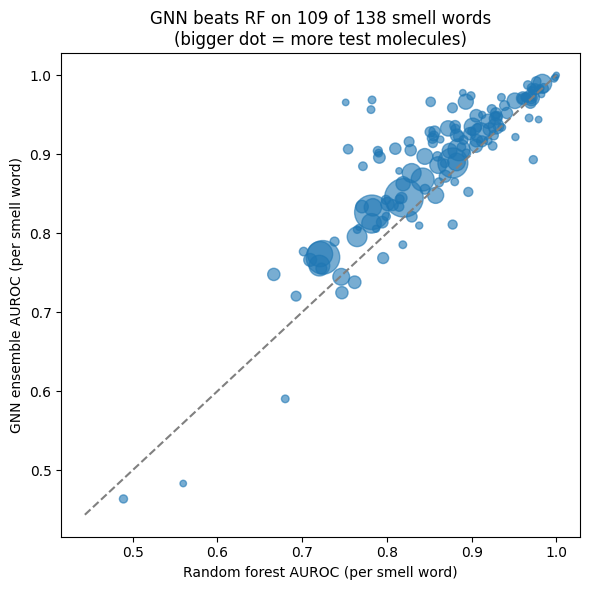

In [2]:
import matplotlib.pyplot as plt
FIG = os.path.expanduser("~/ai-nose/figures"); os.makedirs(FIG, exist_ok=True)
tasks = list(test.tasks)

def per_smell_auroc(y_true, y_prob):
    return np.array([roc_auc_score(y_true[:, j], y_prob[:, j]) for j in range(y_true.shape[1])])

g = per_smell_auroc(test.y, ens_test)   # GNN ensemble, one score per smell word
r = per_smell_auroc(test.y, rf_test)    # random forest
n_pos = test.y.sum(axis=0)              # how many test molecules have each smell

wins = int((g > r).sum())
print(f"GNN beats the random forest on {wins} of {len(tasks)} smell words\n")

order = np.argsort(g - r)
print("Biggest GNN wins:")
for j in order[::-1][:5]:
    print(f"  {tasks[j]:14s} GNN {g[j]:.2f} vs RF {r[j]:.2f}   ({int(n_pos[j])} test molecules)")
print("\nWhere the random forest does better:")
for j in order[:5]:
    print(f"  {tasks[j]:14s} GNN {g[j]:.2f} vs RF {r[j]:.2f}   ({int(n_pos[j])} test molecules)")

lo = min(r.min(), g.min()) - 0.02
plt.figure(figsize=(6, 6))
plt.scatter(r, g, s=10 + 4 * n_pos, alpha=0.6)
plt.plot([lo, 1], [lo, 1], "--", color="gray")
plt.xlabel("Random forest AUROC (per smell word)")
plt.ylabel("GNN ensemble AUROC (per smell word)")
plt.title(f"GNN beats RF on {wins} of {len(tasks)} smell words\n(bigger dot = more test molecules)")
plt.tight_layout()
plt.savefig(f"{FIG}/gnn_vs_rf_per_smell.png", dpi=150)
plt.show()